In [1]:
import regex as re
import pathlib
from IPython.display import Markdown as md

import keras
from keras import ops
from keras import layers
from keras.utils import to_categorical
from keras.utils import text_dataset_from_directory

import collections
import pickle
import matplotlib.pyplot as plt
import numpy as np

import os

### Omschrijving van M\&T blok 2

In dit vak behandelen we verschillende methoden in

::: {.indented-list}
- *natural language processing* (NLP)
- *unsupervised machine learning*,
- *graphical models*,
- *generative models*.
:::
Dit is een uitbreiding van de methoden en technieken uit blok 1. Niet alleen wat betreft algoritmes, maar ook wat betreft terminologie en notatie. Na dit vak zal de student in staat zijn om voor een willekeurig supervised en unsupervised probleem een techniek te gebruiken en deze correct te verantwoorden.


### Docenten

- Robert Nolet (r.w.nolet@hva.nl)
- Michelangelo Vargas (m.vargas.rivera@hva.nl)

Te vinden op de 11de of 13de verdieping van JMH.

### Literatuur
We maken in ieder geval gebruik van onderstaande literatuur, maar zullen gaandeweg ook andere bronnen geven.

::: {.indented-list}
- *An introduction to statistical learning, with Applications in Python* [ISLP]<br>
G. James, D.Witten, T. Hastie, R. Tibshirani en J. Taylor.<br>
Zie [https://www.statlearning.com/](https://www.statlearning.com/){target="_blank"}

- *Probabilistic Machine Learning: An Introduction* [PML1]<br>
K. Murphy<br>
Zie [https://probml.github.io/pml-book/](https://probml.github.io/pml-book/){target="_blank"}<br>

- *Deep learning with Python* [DLP]<br>
F. Chollet<br>
Zie [https://deeplearningwithpython.io/](https://deeplearningwithpython.io/){target="_blank"}
:::

### Toetsing

**Low stake datapunten**<br>

- Wekelijkse opdrachten (geen datapunten, maar wel oefening
en feedback).
- Twee datapunten met deadlines op
    * 2 december 2026 week 4 (woensdag) en
    * 11 januari 2027 week 8 (maandag)

### Rol van M\&T in dit blok
Ook nu zal dit vak losgekoppeld zijn van het project.

Ook nu worden er wel technieken, ideeën en terminologie geïntroduceerd die gebruikt zouden kunnen worden.

::: {.indented-list}
- *NLP*<br>
Zal voor het project nuttig zijn.
- *Unsupervised learning*<br>
Zou in elk domein (bij elk project) nuttig kunnen zijn.
- met *Graphical models*<br>
Introduceren we nieuwe technieken in supervised en unsupervised learning 
- *Generative models*<br>
Introduceren we nieuwe technieken in supervised en unsupervised learning 
:::

### Verantwoording code

Deze slides zijn een Jupyter notebook, de inhoud is grotendeels gebaseerd op H14 uit [*Deep Learning with Python*](https://deeplearningwithpython.io/), de code komt grotendeels van<br>
[https://github.com/fchollet/deep-learning-with-python-notebooks](https://github.com/fchollet/deep-learning-with-python-notebooks)<br>
en<br>
[https://keras.io/examples/nlp/](https://keras.io/examples/nlp/)

<br>
<br>

Dit notebook kan uitgevoerd in een zelfde omgeving als gebruikt in Blok 1 met het toevoegen van de modules **regex**, **tensorflow** en **transformers**.


### Natural language processing (NLP)
"Natural" in NLP staat voor menselijke talen (zoals Italiaans en Nederlands).

In tegenstelling tot door mensen ontwerpen talen voor machines (zoals XML, C en LaTeX).

NLP is lastig, omdat de menselijke taal onder andere

::: {.indented-list}
- **gebruik maakt van uitzonderingen**<br>
uitspraak van "murw" of "lepel", spelling van "apetrots" en "apenstreek"
- **dubbelzinnig kan zijn**<br>
"dit is een foto van Jan", meervoud van "groente", "geluidhinder" en "geluidshinder"
- **kan veranderen**<br>
["pannekoek" werd "pannenkoek" (1995)](https://onzetaal.nl/schatkamer/lezen/taal-en-maatschappij/spelling-geschiedenis/1995-het-tweede-groene-boekje-ruzie-over-de-tussen-n/),<br>
["appèl" (1863) werd "appel" (1954) werd "appèl" (1995) werd "appel" (2005)](https://onzetaal.nl/taalloket/appel)
:::


### Pogingen voor NLP

* Start na de Tweede Wereldoorlog waar men het zag als 'code kraken'.

* Opbouw vanuit regels (vanaf jaren 50 vorige eeuw)

* Vanaf eind jaren 80 vorige eeuw: ML<br>
beslisbomen, logistische regressie en feature engineering

* Rond 2014-2015: NLP met RNN's zoals LSTM (jaren 90 vorige eeuw)

* Rond 2017-2018: the Transformer (ChatGPT)

### Hoe wordt NLP gebruikt?
Niet om taal te begrijpen, maar als een methode om statistische eigenschappen in tekst te vinden. Met deze eigenschappen kunnen we iets nuttigs zeggen over een specifiek stuk tekst.

::: {.indented-list}
- Wat is het onderwerp van deze tekst? (classificatie)
- Bevat deze tekst scheldwoorden of ander misbruik? (content filtering)
- Is de tekst positief of negatief? (sentiment analysis)
- Wat is het volgende woord in deze incomplete zin? (language modeling)
- Hoe zeg je dit in het Duits? (vertalen)
- Hoe vat je deze paragraaf samen? (samenvatten)
:::

### Vectorizing (tokenizing) tekst
Neurale netwerken (en veel andere modellen) hebben als invoer getallen nodig.

Vectorizing (of tokenizing) bestaat uit

::: {.indented-list}
- **Standardization**<br>
Vereenvoudig de tekst door bijvoorbeeld

::: {.indented-list}
- leestekens te negeren,
- hoofdletters te veranderen in kleine letters,
- accenten op letters te negeren,
- stopwoorden te verwijderen.
:::
- **Splitting**<br>
Splits de symbolen (*tokens*) waarmee je wil werken. Zijn dat de karakters, de woorden of woordgroepen?
- **Indexing**<br>
Elk symbool (*token*) krijgt een getal toegewezen.
:::

### Tekststandaardisatie
Vorm van feature engineering

Vermijd overbodigheid. Is het nodig om een verschil te maken tussen

- "Duits" en "duits",
- "enqûete" en "enquete",
- "ik loop, omdat" en "ik loop omdat",
- "hoe heet jij?" en "hoe heet jij",
- "hij liep", "hij loopt" en "hij [lopen]" (*stemming* of *lemmatization*),
- "het huis en de tuin", "huis tuin"?

Model heeft zo minder data nodig en generaliseert beter. 

Maar (zie [DLP]),

"For the larger models used today, most standardization is as light as possible ..."

In [2]:
def split_chars(text):
    return re.findall(r".", text)

def split_words(text):
    return re.findall(r"[\w]+|[.,!?;]", text)

zin = 'Allen die zich in Nederland bevinden, worden in gelijke gevallen gelijk behandeld. Discriminatie wegens godsdienst, levensovertuiging, politieke gezindheid, ras, geslacht, handicap, seksuele gerichtheid of op welke grond dan ook, is niet toegestaan.'


### Splitsen naar *tokens*

Voorbeeld: Eerste artikel van de Nederlandse Grondwet.

In [3]:
zin

'Allen die zich in Nederland bevinden, worden in gelijke gevallen gelijk behandeld. Discriminatie wegens godsdienst, levensovertuiging, politieke gezindheid, ras, geslacht, handicap, seksuele gerichtheid of op welke grond dan ook, is niet toegestaan.'

- Woordniveau: splits op de spaties (en leestekens).<br>

In [4]:
def truncate_list(lijst, n=4):
    begin = lijst[:n]
    eind = lijst[-n:]
    x = str(begin)[:-1]+", "
    y = " ,"+str(eind)[1:]
    print(f"{x} ... {y}")

truncate_list(split_words(zin))

['Allen', 'die', 'zich', 'in',  ...  ,'is', 'niet', 'toegestaan', '.']


In [5]:

Woord_aantal = len(split_words(zin))
unieke_woorden = len(set(split_words(zin)))

md("Aantal tokens is gelijk aan %i"%(Woord_aantal)+
   ". Aantal unieke tokens is gelijk aan %i"%(unieke_woorden))

Aantal tokens is gelijk aan 42. Aantal unieke tokens is gelijk aan 33

<br>

- Karakterniveau: Splits alle karakters.


In [6]:
truncate_list(split_chars(zin))

['A', 'l', 'l', 'e',  ...  ,'a', 'a', 'n', '.']


In [7]:
Letter_aantal = len(split_chars(zin))
unieke_letters = len(set(split_chars(zin)))

md("Aantal tokens is gelijk aan %i"%(Letter_aantal)+
   ". Aantal unieke tokens is gelijk aan %i"%(unieke_letters))

Aantal tokens is gelijk aan 249. Aantal unieke tokens is gelijk aan 29

### Indexing
Relateer een uniek geheel getal aan (bijna) elk symbool uit de trainset (*vocabulary*, woordenlijst, symbolenlijst).

Gebruikelijk om alleen de N meest voorkomende symbolen te gebruiken.

We reserveren de index-waarden 0 en 1 voor speciale gevallen.

- De index-waarde 0 wordt gebruikt als *mask token*.<br>
Een symbool dat genegeert mag worden en gebruikt wordt om aan te vullen (*padding* van rijen).<br>
Dit zal vooral voor sequence models van belang zijn.
- De index-waarde 1 wordt gebruikt als *"out of vocabulary”-index* (of OOV-index).<br>
Een symbool voor woorden die niet in de woordenlijst voorkomen.

De overige indices staan voor de symbolen op volgorde van hoe vaak ze voorkomen. Omgekeerd alfabetisch bij gelijk spel.

### Voor- en nadeel van splitsen op woorden

In [8]:
text_vectorization = layers.TextVectorization(
output_mode="int",
)

filename = r"C:\Users\Ik\Desktop\2026-2027\AAI\Blok_2\Slides\Concepten\Data\Grondwet_voor_het_Koninkrijk_der_Nederlanden_(2023).txt"

dataset = list(open(filename, "r"))


We lezen de Nederlandse grondwet in (zie<br>
[https://nl.wikisource.org/wiki/Grondwet_voor_het_Koninkrijk_der_Nederlanden_(2023)](https://nl.wikisource.org/wiki/Grondwet_voor_het_Koninkrijk_der_Nederlanden_(2023)) en [https://www.denederlandsegrondwet.nl/](https://www.denederlandsegrondwet.nl/))

In [9]:
text_vectorization.adapt(dataset)

vocabulary = text_vectorization.get_vocabulary()

inverse_vocab = dict(enumerate(vocabulary))

De *vocabulary* is:

In [10]:
def truncate_rechts(lijst, n=8):
    begin = lijst[:n]
    x = str(begin)[:-1] + ",   "
    y = "]"
    print(f"{x} ... {y}")

truncate_rechts([str(token) for token in vocabulary])

['', '[UNK]', 'de', 'van', 'het', 'en', 'in', 'artikel',    ... ]


In [11]:
aantal_grondwet = len(vocabulary)
md("en bestaat uit %i"%(aantal_grondwet)+
   " woorden (tokens)")


en bestaat uit 2596 woorden (tokens)

In [ ]:
test_sentence = "'Staan al deze woorden en karakters in de Grondwet of niet?'"
test_sentence = "'België is een federale Staat, samengesteld uit de gemeenschappen en de gewesten.'"
md("testzin:<br>"+test_sentence)

testzin:<br>'België is een federale Staat, samengesteld uit de gemeenschappen en de gewesten.'

[https://www.belgischegrondwet.be/de-belgische-grondwet/huidige-grondwet](https://www.belgischegrondwet.be/de-belgische-grondwet/huidige-grondwet)

In [13]:
encoded_sentence = text_vectorization(test_sentence)
decoded_sentence = " ".join(inverse_vocab[int(i)] for i in encoded_sentence)

In [14]:
 
"gecodeerde zin is: "+str(encoded_sentence.numpy())

'gecodeerde zin is: [   1   10    8    1  135 1772   59    2    1    5    2    1]'

In [15]:
"gedecodeerde zin is : "+str(decoded_sentence)

'gedecodeerde zin is : [UNK] is een [UNK] staat samengesteld uit de [UNK] en de [UNK]'

Nadeel van splitsen op woorden is dat men '[UNK]' voor lief moet nemen of een zeer grote vocabulary moet hanteren.

### Wat als we splitsen op karakters?

De *vocabulary* is:

In [16]:
text_vectorization = layers.TextVectorization(
    split = "character",
    output_mode="int",
)
text_vectorization.adapt(dataset)

vocabulary = text_vectorization.get_vocabulary()

inverse_vocab = dict(enumerate(vocabulary))

truncate_rechts([str(token) for token in vocabulary])

['', '[UNK]', 'e', ' ', 'n', 't', 'i', 'a',    ... ]


In [17]:
aantal_grondwet = len(vocabulary)
md("en bestaat uit %i"%(aantal_grondwet)+
   " karakters (tokens)")

en bestaat uit 55 karakters (tokens)

In [18]:
md("testzin:<br>"+test_sentence)

testzin:<br>'België is een federale Staat, samengesteld uit de gemeenschappen en de gewesten.'

In [19]:
encoded_sentence = text_vectorization(test_sentence)
decoded_sentence = " ".join(inverse_vocab[int(i)] for i in encoded_sentence)

In [20]:
 
"gecodeerde zin is: "+str(encoded_sentence.numpy())

'gecodeerde zin is: [18  2 12 11  6 40  3  6 13  3  2  2  4  3 26  2  9  2  8  7 12  2  3 13\n  5  7  7  5  3 13  7 19  2  4 11  2 13  5  2 12  9  3 23  6  5  3  9  2\n  3 11  2 19  2  2  4 13 22 16  7 24 24  2  4  3  2  4  3  9  2  3 11  2\n 20  2 13  5  2  4]'

In [21]:
"gedecodeerde zin is : "+str(decoded_sentence)

'gedecodeerde zin is : b e l g i ë   i s   e e n   f e d e r a l e   s t a a t   s a m e n g e s t e l d   u i t   d e   g e m e e n s c h a p p e n   e n   d e   g e w e s t e n'

Nadeel van splitsen op karakters is dat de zinnen zeer lang worden.

### Alternatief: subword tokenization

* Beschouw elk uniek woord als een opeenvolging van losse karakters (tokens)
* Beschouw de opeenvolgende paren van karakters in een woord
* Voeg de meest voorkomende paren (rekening houdend met woordvolgorde) samen tot een nieuw token
* Stop als het maximaal aantal tokens is bereikt

In [22]:
def count_and_split_words(data):
    counts = collections.Counter()
    for line in data:
        line = line.lower()
        for word in re.findall(r"[\w]+|[.,!?;]", line):
            chars = re.findall(r".", word)
            split_word = " ".join(chars)
            counts[split_word] += 1
    return dict(counts)

counts = count_and_split_words([zin])

def count_pairs(counts):
    pairs = collections.Counter()
    for word, freq in counts.items():
        symbols = word.split()
        for pair in zip(symbols[:-1], symbols[1:]):
            pairs[pair] += freq
    return pairs

def merge_pair(counts, first, second):
    # Matches an unmerged pair
    split = re.compile(f"(?<!\\S){first} {second}(?!\\S)")
    # Replaces all occurances with a merged version
    merged = f"{first}{second}"
    return {split.sub(merged, word): count for word, count in counts.items()}

for i in range(10):
    pairs = count_pairs(counts)
    first, second = max(pairs, key=pairs.get)
    counts = merge_pair(counts, first, second)
    truncate_rechts(list(counts.keys()), 9)


['a l l e n', 'd i e', 'z i c h', 'i n', 'n e d e r l a n d', 'b e v i n d e n', ',', 'w o r d e n', 'ge l i j k e',    ... ]
['a l l en', 'd i e', 'z i c h', 'i n', 'n e d e r l a n d', 'b e v i n d en', ',', 'w o r d en', 'ge l i j k e',    ... ]
['a l l en', 'd i e', 'z i c h', 'in', 'n e d e r l a n d', 'b e v in d en', ',', 'w o r d en', 'ge l i j k e',    ... ]
['a l l en', 'd i e', 'z i c h', 'in', 'n e d e r l an d', 'b e v in d en', ',', 'w o r d en', 'ge l i j k e',    ... ]
['a l l en', 'di e', 'z i c h', 'in', 'n e d e r l an d', 'b e v in d en', ',', 'w o r d en', 'ge l i j k e',    ... ]
['a l l en', 'di e', 'z i ch', 'in', 'n e d e r l an d', 'b e v in d en', ',', 'w o r d en', 'ge l i j k e',    ... ]
['a l l en', 'di e', 'z i ch', 'in', 'n e d e r l an d', 'b e v in d en', ',', 'w o r d en', 'ge li j k e',    ... ]
['a l l en', 'di e', 'z i ch', 'in', 'n e d e r l an d', 'b e v in d en', ',', 'w o r d en', 'ge li j ke',    ... ]
['a l l en', 'di e', 'z i ch', 'in', 'n 

### Subword tokenization, vervolg

In [23]:
def compute_sub_word_vocabulary(dataset, vocab_size):
    counts = count_and_split_words(dataset)

    char_counts = collections.Counter()
    for word in counts:
        for char in word.split():
            char_counts[char] += counts[word]
    most_common = char_counts.most_common()
    vocab = ["[UNK]"] + [char for char, freq in most_common]
    merges = []

    while len(vocab) < vocab_size:
        pairs = count_pairs(counts)
        if not pairs:
            break
        first, second = max(pairs, key=pairs.get)
        counts = merge_pair(counts, first, second)
        vocab.append(f"{first}{second}")
        merges.append(f"{first} {second}")

    vocab = dict((token, index) for index, token in enumerate(vocab))
    merges = dict((token, rank) for rank, token in enumerate(merges))
    return vocab, merges

class SubWordTokenizer:
    def __init__(self, vocabulary, merges):
        self.vocabulary = vocabulary
        self.merges = merges
        self.unk_id = vocabulary["[UNK]"]

    def standardize(self, inputs):
        return inputs.lower()

    def bpe_merge(self, word):
        while True:
            # Matches all symbol pairs in the text
            pairs = re.findall(r"(?<!\S)\S+ \S+(?!\S)", word, overlapped=True)
            if not pairs:
                break
            # We apply merge rules in "rank" order. More frequent pairs
            # are merged first.
            best = min(pairs, key=lambda pair: self.merges.get(pair, 1e9))
            if best not in self.merges:
                break
            first, second = best.split()
            split = re.compile(f"(?<!\\S){first} {second}(?!\\S)")
            merged = f"{first}{second}"
            word = split.sub(merged, word)
        return word

    def split(self, inputs):
        tokens = []
        # Split words
        for word in re.findall(r"[\w]+|[.,!?;]", inputs):
            # Joins all characters with a space
            word = " ".join(re.findall(r".", word))
            # Applies byte-pair encoding merge rules
            word = self.bpe_merge(word)
            tokens.extend(word.split())
        return tokens

    def index(self, tokens):
        return [self.vocabulary.get(t, self.unk_id) for t in tokens]

    def __call__(self, inputs):
        inputs = self.standardize(inputs)
        tokens = self.split(inputs)
        indices = self.index(tokens)
        return indices
    
vocabulary, merges = compute_sub_word_vocabulary(dataset, 2_000)
sub_word_tokenizer = SubWordTokenizer(vocabulary, merges)

De *vocabulary* is nu:

In [24]:
truncate_list(list(vocabulary.keys()), 6)

['[UNK]', 'e', 'n', 't', 'i', 'a',  ...  ,'opp', 'verplicht', '99', '100', 'verlening', 'gew']


In [25]:
aantal_grondwet_subwords = len(vocabulary)
md("en bestaat uit %i"%(aantal_grondwet_subwords)+
   " tokens")

en bestaat uit 2000 tokens

In [26]:
md("testzin:<br>"+test_sentence)

testzin:<br>'België is een federale Staat, samengesteld uit de gemeenschappen en de gewesten.'

In [27]:
encoded_sentence = sub_word_tokenizer(test_sentence)
inverse_vocab = dict(enumerate(vocabulary))
decoded_sentence = " ".join(inverse_vocab[int(i)] for i in encoded_sentence)

In [28]:
"gecodeerde zin is: "+str(encoded_sentence)

'gecodeerde zin is: [188, 9, 4, 37, 82, 75, 697, 76, 210, 253, 25, 421, 369, 93, 48, 172, 243, 411, 47, 48, 1530, 1006, 22]'

In [29]:
"gedecodeerde zin is: "+str(decoded_sentence)

'gedecodeerde zin is: bel g i ë is een fe der ale staat , samen gesteld uit de gemeen schap pen en de gewe sten .'

<br>
Nadeel: preparatiestap duurt langer.

### Wanneer welke splitsing?

Hangt af van de situatie.

* Splitsen op woorden is simpel en begrijpbaar.<br>
Dit maakt het rangschikken van tokens (om te voorspellen) eenvoudig te interpreteren.
* Spliten op karakters zou goed kunnen werken in een situatie waarin je spellings-correctie zou wilen gebruiken.
* Subword tokenization is het populaire alternatief en wordt gebruikt in de meeste moderne taalmodellen.

### Structuur van tekst

We hebben tekst nu gerepresenteerd als een rij van getallen.

* Deze getallen moeten worden gezien als klasses<br>
Wat betekent dit voor het aantal variabalen?
* Is volgorde van belang?

We kunnen Tekstverwerkingmodellen classificeren op hoe ze omgaan met tekststructuur

* Sequence models: de invoer is een reeks van woorden (met volgorde)
* Bag-of-words models: N-grams als symbolen. Deze N-grams hebben geen volgorde.

### N-grams en bag-of-words
Voorbeeld van een bag-of-2-grams.
$$
``\textrm{ik ben blij"} \to \{``\textrm{ik"}, ``\textrm{ben"}, ``\textrm{blij"}, ``\textrm{ik ben"}, ``\textrm{ben blij"}\}
$$

Een bag staat voor een multi-set. Een verzameling met herhaling. Volgorde maakt dus niet uit.

Middels de N-grams wordt er een heel lokale volgorde in het model ingevoerd.

Wordt gebruikt in niet-diepe modellen (immers een vorm van *feature engineering*).

### Voorbeeld uit boek [DLP], $\S$ 14.4
IMDB movie reviews data

Labelled data om te bepalen of een filmrecensie positief of negatief is.

50 duizend recensies. Gesplitst (40\%, 10\%, 50\%).

De helft van de recensies is positief (in trainset).

Wat is de score op het nulmodel?<br>
Op welke maat?

Volgens [DLP] (eerdere versie) is de hoogste score die men kan krijgen (zonder gebruik te maken van andere data) een accuraatheid van 95% (op testdata).

### Voorbeeld van een recensie

In [30]:
dname = os.path.join("/Users/Ik/backup_2308/2022-2023/AAI/MenT/Chollet/")
fname = os.path.join(dname, "aclImdb/train/pos/4077_10.txt")

with open(fname) as f:
     print(f.read())

I first saw this back in the early 90s on UK TV, i did like it then but i missed the chance to tape it, many years passed but the film always stuck with me and i lost hope of seeing it TV again, the main thing that stuck with me was the end, the hole castle part really touched me, its easy to watch, has a great story, great music, the list goes on and on, its OK me saying how good it is but everyone will take there own best bits away with them once they have seen it, yes the animation is top notch and beautiful to watch, it does show its age in a very few parts but that has now become part of it beauty, i am so glad it has came out on DVD as it is one of my top 10 films of all time. Buy it or rent it just see it, best viewing is at night alone with drink and food in reach so you don't have to stop the film.<br /><br />Enjoy


### bag-of-words-aanpak
Kies de 20 duizend meest voorkomende woorden voor in de woordenlijst.

Maak gebruik van 1-grams.

Maak gebruik van multi-hot-encoding:

* Elke waarneming (recensie) is een vector van lengte 20 duizend
* Elk element in de vector is een 0 of een 1

Loss: binary cross entropy, Metriek: accuracy, Early stopping: patience=2

In [31]:
train_dir = pathlib.Path("C:/Users/Ik/.keras/datasets/imdb/imdb_train")
test_dir = pathlib.Path("C:/Users/Ik/.keras/datasets/imdb/imdb_test")
val_dir = pathlib.Path("C:/Users/Ik/.keras/datasets/imdb/imdb_val")

In [32]:
#| output: false
batch_size = 32
train_ds = text_dataset_from_directory(train_dir, batch_size=batch_size)
val_ds = text_dataset_from_directory(val_dir, batch_size=batch_size)
test_ds = text_dataset_from_directory(test_dir, batch_size=batch_size)

Found 20000 files belonging to 2 classes.
Found 5000 files belonging to 2 classes.
Found 25000 files belonging to 2 classes.


In [33]:
#| output: false
max_tokens = 20_000

text_vectorization = layers.TextVectorization(
    max_tokens=max_tokens,
    split="whitespace",
    output_mode="multi_hot",
)
train_ds_no_labels = train_ds.map(lambda x, y: x)
text_vectorization.adapt(train_ds_no_labels)

bag_of_words_train_ds = train_ds.map(
    lambda x, y: (text_vectorization(x), y), num_parallel_calls=8
)
bag_of_words_val_ds = val_ds.map(
    lambda x, y: (text_vectorization(x), y), num_parallel_calls=8
)
bag_of_words_test_ds = test_ds.map(
    lambda x, y: (text_vectorization(x), y), num_parallel_calls=8
)

def build_linear_classifier(max_tokens, name):
    inputs = keras.Input(shape=(max_tokens,))
    outputs = layers.Dense(1, activation="sigmoid")(inputs)
    model = keras.Model(inputs, outputs, name=name)
    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"],
    )
    return model

model = build_linear_classifier(max_tokens, "bag_of_words_classifier")

In [34]:
#| output: false
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    restore_best_weights=True,
    patience=2,
    verbose=1,
)

In [35]:
#| output: false
model = build_linear_classifier(max_tokens, "bag_of_words_classifier")
naam = model.name
model_pad = "models/"+naam+".keras"
hist_pad = "models/"+naam+".hist"

history = model.fit(
    bag_of_words_train_ds,
    validation_data=bag_of_words_val_ds,
    epochs=10, #was 10
    callbacks=[early_stopping],
)

with open(hist_pad, 'wb') as file:
    pickle.dump(history.history, file)

model.save(model_pad)

# Minder dan twee minuten op CPU

Epoch 1/10


c:\Users\Ik\anaconda3\envs\TEST_MenT2627\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


625/625 ━━━━━━━━━━━━━━━━━━━━ 13s 19ms/step - accuracy: 0.8398 - loss: 0.4592 - val_accuracy: 0.8824 - val_loss: 0.3604
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.9073 - loss: 0.2937 - val_accuracy: 0.8892 - val_loss: 0.3082
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - accuracy: 0.9288 - loss: 0.2362 - val_accuracy: 0.8910 - val_loss: 0.2834
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.9427 - loss: 0.2006 - val_accuracy: 0.8948 - val_loss: 0.2725
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.9527 - loss: 0.1752 - val_accuracy: 0.8932 - val_loss: 0.2667
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.9604 - loss: 0.1552 - val_accuracy: 0.8944 - val_loss: 0.2631
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.9663 - loss: 0.1390 - val_accuracy: 0.8952 - val_loss: 0.2621
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - accuracy: 0.9714 - loss: 0.1252 - val_accuracy: 0.8952 -

### Het 'bag of words'-model

<br>

In [36]:
model = keras.saving.load_model("models/bag_of_words_classifier.keras")
model.summary()

Model: "bag_of_words_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 20000)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │        20,001 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 60,005 (234.40 KB)

 Trainable params: 20,001 (78.13 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 40,004 (156.27 KB)

In [37]:
def laad_geschiedenis(naam, colab=0):
    if colab==1:
        with open("/Users/Ik/Desktop/2023-2024/AAI/MenT/Notebooks/models/"+naam+".hist", 'rb') as file:
            history = pickle.load(file)
    else:
        with open("models/"+naam+".hist", 'rb') as file:
            history = pickle.load(file)
    return history

def afbeelding(naam, colab=0):
    geschiedenis = laad_geschiedenis(naam, colab)
    accuracy = geschiedenis["accuracy"]
    val_accuracy = geschiedenis["val_accuracy"]
    epochs = range(1, len(accuracy) + 1)
    plt.figure()
    plt.plot(epochs, accuracy, "b-", label="Training")
    plt.plot(epochs, val_accuracy, "y-", label="Validatie")
    #plt.plot(epochs, [0.5]*len(epochs), 'r--', label='Nulmodel')
    plt.xlabel('Epochs')
    plt.ylabel('accuraatheid')
    plt.title("Training- and validatie-accuraatheid, "+naam)
    plt.legend()
    plt.show()

### Het 'bag of words'-model - Resultaat

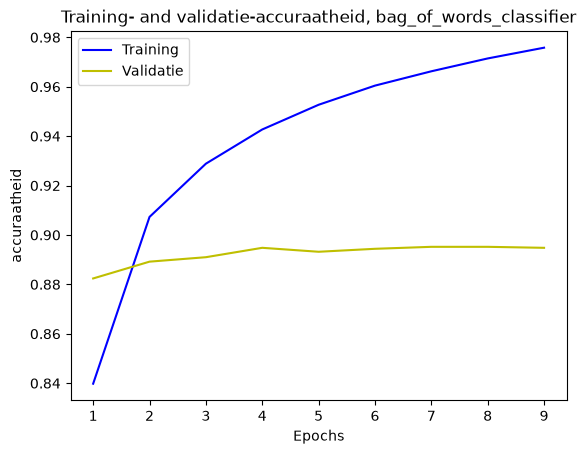

In [38]:
afbeelding("bag_of_words_classifier")

In [39]:
def validatie_uitslag(naam, colab=0):
    if colab==1:
        if os.path.isfile("/Users/Ik/Desktop/2023-2024/AAI/MenT/Notebooks/models/"+naam+".hist"):
            geschiedenis = laad_geschiedenis(naam, colab)
            hoogst = np.max(geschiedenis["val_accuracy"])
            print("Beste Validatie-accuraatheid van "+naam+f": {hoogst:.3f}")
        else:
            print("Geen correcte naam opgegeven")
    else:
        if os.path.isfile("models/"+naam+".hist"):
            geschiedenis = laad_geschiedenis(naam)
            hoogst = np.max(geschiedenis["val_accuracy"])
            print("Validatie-accuraatheid bij laagste loss van "+naam+f": {hoogst:.3f}")
        else:
            print("Geen correcte naam opgegeven")

In [40]:
validatie_uitslag("bag_of_words_classifier")

Validatie-accuraatheid bij laagste loss van bag_of_words_classifier: 0.895


### [$\texttt{TextVectorization}$](https://keras.io/api/layers/preprocessing_layers/text/text_vectorization/) werkt alleen op CPU
$\texttt{TextVectorization}$ kan zowel in datapreparatie-stap als in model gedeclareerd worden.

Als je GPU gebruikt, is het sneller als je het in de data-preparatie declareert.

Als je het ergens inplementeert, wil je liever een model leveren waar de data-preparatie al in zit (als laag).

Zie paragraaf 14.4 van [DLP] voor meer hierover.

### Hetzelfde model met 2-grams
De symbolen (tokens) zijn nu woorden en paren van opeenvolgende woorden.

We maken een vocabulary van 30 duizend symbolen.

Zeer kleine verbetering (anders dan boek?)

In [41]:
max_tokens = 30_000
text_vectorization = layers.TextVectorization(
    max_tokens=max_tokens,
    split="whitespace",
    output_mode="multi_hot",
    ngrams=2,
)
text_vectorization.adapt(train_ds_no_labels)

bigram_train_ds = train_ds.map(
    lambda x, y: (text_vectorization(x), y), num_parallel_calls=8
)
bigram_val_ds = val_ds.map(
    lambda x, y: (text_vectorization(x), y), num_parallel_calls=8
)
bigram_test_ds = test_ds.map(
    lambda x, y: (text_vectorization(x), y), num_parallel_calls=8
)

### Het bigram-model

In [42]:
#| output: false
model = build_linear_classifier(max_tokens, "bigram_classifier")

naam = model.name
model_pad = "models/"+naam+".keras"
hist_pad = "models/"+naam+".hist"

history = model.fit(
    bigram_train_ds,
    validation_data=bigram_val_ds,
    epochs=10, #was 10
    callbacks=[early_stopping],
)

with open(hist_pad, 'wb') as file:
    pickle.dump(history.history, file)

model.save(model_pad)

# Minder dan 2 minuten op CPU


Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.8608 - loss: 0.3993 - val_accuracy: 0.8914 - val_loss: 0.3082
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.9367 - loss: 0.2230 - val_accuracy: 0.9030 - val_loss: 0.2688
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.9610 - loss: 0.1638 - val_accuracy: 0.9074 - val_loss: 0.2542
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.9751 - loss: 0.1273 - val_accuracy: 0.9072 - val_loss: 0.2485
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.9839 - loss: 0.1015 - val_accuracy: 0.9078 - val_loss: 0.2470
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.9893 - loss: 0.0822 - val_accuracy: 0.9058 - val_loss: 0.2488
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.9937 - loss: 0.0670 - val_accuracy: 0.9060 - val_loss: 0.2510
Epoch 7: early stopping
Restoring model weights from the end of the best epoch: 5.


In [43]:
model = keras.saving.load_model("models/bigram_classifier.keras")
model.summary()

Model: "bigram_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 30000)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │        30,001 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 90,005 (351.59 KB)

 Trainable params: 30,001 (117.19 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 60,004 (234.39 KB)

### Het bigram-model - resultaat

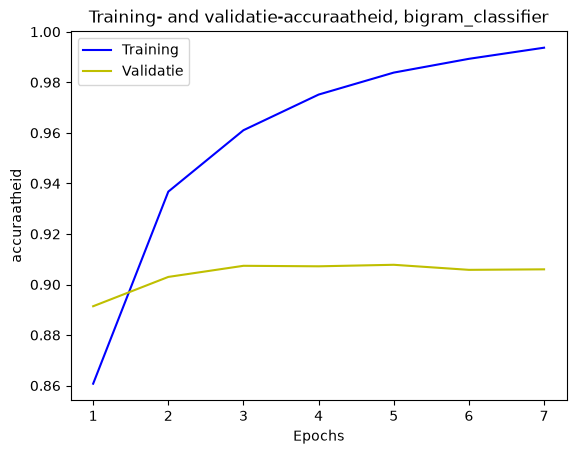

In [44]:
afbeelding("bigram_classifier")

In [45]:
validatie_uitslag("bigram_classifier")

Validatie-accuraatheid bij laagste loss van bigram_classifier: 0.908


### Alternatieven  voor multi-hot-encoding

* Tel hoe vaak een woord voorkomt
* TF-IDF: term frequency, inverse document frequency
    * Hoe vaker een woord voorkomt in een tekst hoe belangrijker.
    * Hoe meer teksten dat woord bevatten hoe minder belangrijk.

Zoals multi-hot, maar dan met
$$
\frac{\textrm{frequentie woord tekst}}{\log(\textrm{frequentie teksten met het woord} + 1)}.
$$